
Original Dataset:
   Age  Salary  Experience  Marks
0   20   20000           1     60
1   25   25000           2     65
2   30   30000           5     70
3   35   35000           7     75
4   40   40000          10     80
5   45   45000          12     85
6   50   50000          15     90
7   55   55000          18     95

Dataset After Feature Engineering:
   Age  Salary  Experience  Marks  Salary_Per_Experience Age_Group
0   20   20000           1     60           20000.000000     Young
1   25   25000           2     65           12500.000000     Young
2   30   30000           5     70            6000.000000    Middle
3   35   35000           7     75            5000.000000    Middle
4   40   40000          10     80            4000.000000    Middle
5   45   45000          12     85            3750.000000    Senior
6   50   50000          15     90            3333.333333    Senior
7   55   55000          18     95            3055.555556    Senior

Numerical Features:
   Age  Salary 

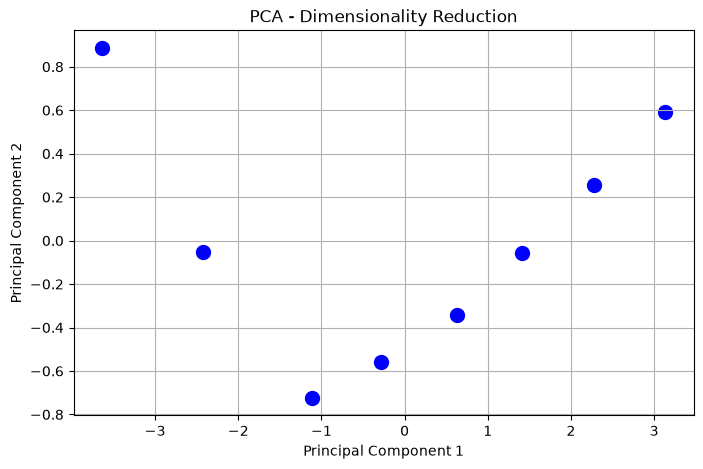

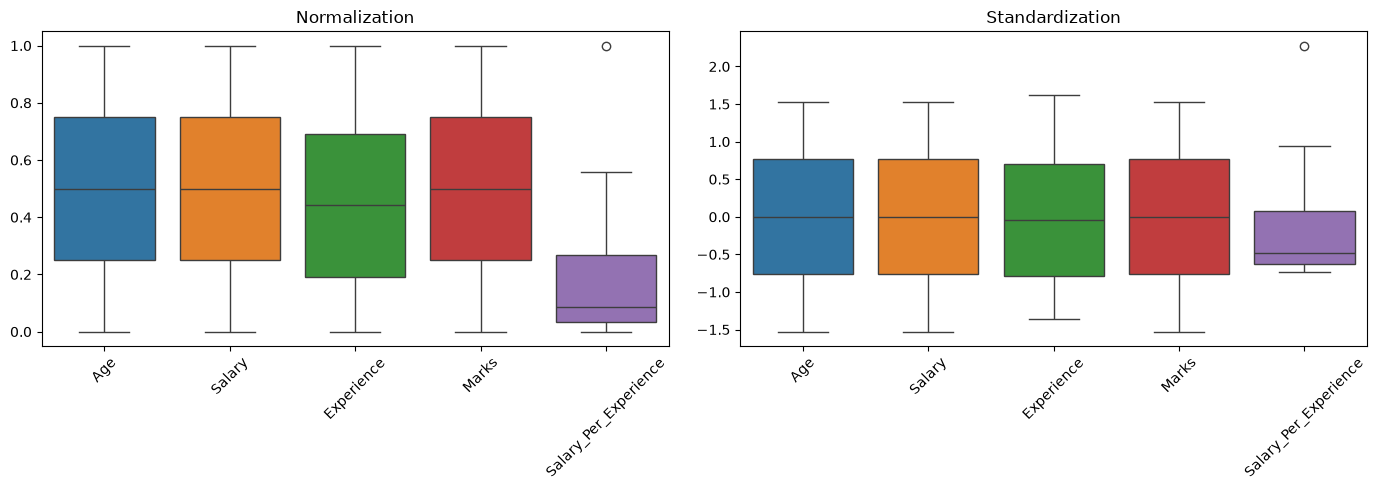

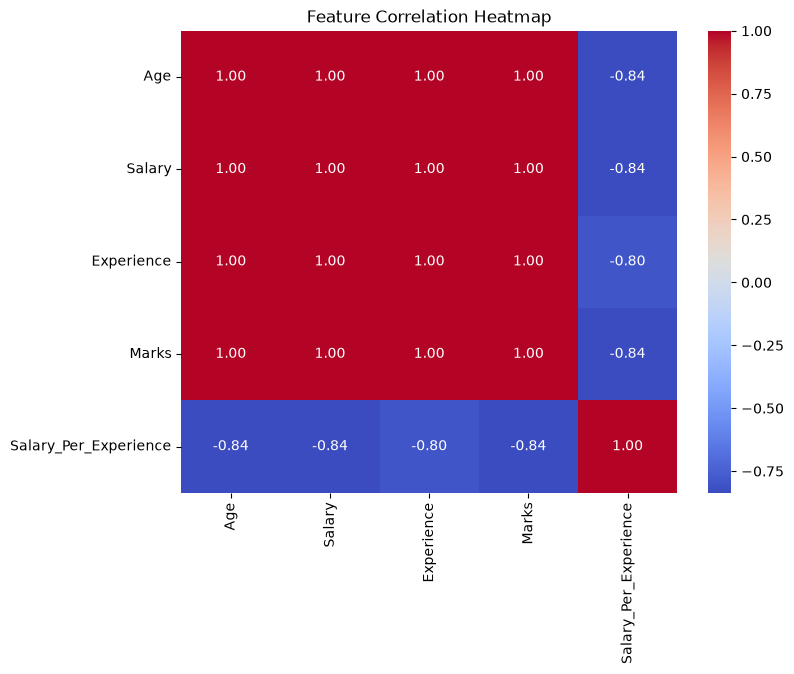


========== FINAL SUMMARY ==========
Original Number of Features: 5
PCA Number of Features: 2
Variance Retained: 99.95 %

Program Completed Successfully!


In [1]:

# ============================================
# FEATURE ENGINEERING, NORMALIZATION,
# STANDARDIZATION AND PCA
# ============================================

# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA


# 2. Create Dataset

data = {
    'Age': [20, 25, 30, 35, 40, 45, 50, 55],
    'Salary': [20000, 25000, 30000, 35000,
               40000, 45000, 50000, 55000],
    'Experience': [1, 2, 5, 7, 10, 12, 15, 18],
    'Marks': [60, 65, 70, 75, 80, 85, 90, 95]
}

df = pd.DataFrame(data)

print("\nOriginal Dataset:")
print(df)


# 3. Feature Engineering

# Create new feature
df['Salary_Per_Experience'] = (
    df['Salary'] / df['Experience']
)

# Create age group
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[0, 25, 40, 60],
    labels=['Young', 'Middle', 'Senior']
)

print("\nDataset After Feature Engineering:")
print(df)


# 4. Select Numerical Features

numerical_data = df.select_dtypes(
    include=np.number
)

print("\nNumerical Features:")
print(numerical_data)


# 5. Normalization (Min-Max Scaling)

normalizer = MinMaxScaler()

normalized_data = normalizer.fit_transform(
    numerical_data
)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=numerical_data.columns
)

print("\nNormalized Data:")
print(normalized_df)


# 6. Standardization (Z-Score Scaling)

scaler = StandardScaler()

standardized_data = scaler.fit_transform(
    numerical_data
)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=numerical_data.columns
)

print("\nStandardized Data:")
print(standardized_df)


# 7. Principal Component Analysis (PCA)

pca = PCA(n_components=2)

pca_data = pca.fit_transform(
    standardized_data
)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

print("\nPCA Reduced Dataset:")
print(pca_df)


# 8. Explained Variance

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(sum(pca.explained_variance_ratio_))


# 9. PCA Visualization

plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    s=100
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - Dimensionality Reduction')

plt.grid(True)
plt.show()


# 10. Compare Normalization and Standardization

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=normalized_df)
plt.title('Normalization')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(data=standardized_df)
plt.title('Standardization')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# 11. Correlation Heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    numerical_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.show()


# 12. Final Results

print("\n========== FINAL SUMMARY ==========")

print("Original Number of Features:",
      numerical_data.shape[1])

print("PCA Number of Features:",
      pca_df.shape[1])

print("Variance Retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2),
      "%")

print("\nProgram Completed Successfully!")
